In [ ]:
!pip install -q "monai[nibabel]"

import os
import glob
import time
import torch
from monai.data import CacheDataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd,
    Orientationd, NormalizeIntensityd,
    RandCropByPosNegLabeld, ToTensord
)
from monai.networks.nets import UNet
from monai.losses import DiceCELoss

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 30.9 MB/s eta 0:00:00


In [ ]:
import os
import glob
import h5py
import numpy as np
import torch
from monai.data import CacheDataset, DataLoader
from monai.transforms import (
    Compose, MapTransform, SpatialPadd, NormalizeIntensityd,
    RandCropByPosNegLabeld, ToTensord
)

# 1. Custom HDF5 Loader for MONAI
class LoadACDCH5d(MapTransform):
    def __call__(self, data):
        d = dict(data)
        filepath = d[self.keys[0]]
        with h5py.File(filepath, 'r') as f:
            # Load arrays and add the channel dimension required by PyTorch -> (1, Depth, Height, Width)
            d['image'] = np.expand_dims(f['image'][:], axis=0).astype(np.float32)
            d['label'] = np.expand_dims(f['label'][:], axis=0).astype(np.float32)
        return d

# 2. Locate the H5 files
train_dir = "/content/ACDC_Data/ACDC_preprocessed/ACDC_training_volumes"
train_files = sorted(glob.glob(f"{train_dir}/*.h5"))

if not train_files:
    raise FileNotFoundError(f"No .h5 files found in {train_dir}!")

# Structure the dictionaries for the custom loader
data_dicts = [{"h5_path": f} for f in train_files]

# Split 80% for training
train_size = int(0.8 * len(data_dicts))
train_data = data_dicts[:train_size]
print(f"Allocated {len(train_data)} volumes for training.")

# 3. Define Preprocessing Pipeline with Dimensionality Safety
train_transforms = Compose([
    LoadACDCH5d(keys=["h5_path"]),
    NormalizeIntensityd(keys=["image"], nonzero=True, channel_wise=True),

    # Pad depth from ~10 up to 16 so the U-Net convolutions don't crash
    SpatialPadd(keys=["image", "label"], spatial_size=(16, 256, 240)),

    # Crop a safe 3D patch centered around the heart
    RandCropByPosNegLabeld(
        keys=["image", "label"],
        label_key="label",
        spatial_size=(16, 128, 128),
        pos=1, neg=1, num_samples=4,
    ),
    ToTensord(keys=["image", "label"]),
])

# 4. Cache and Load Dataset
print("Caching dataset into Colab RAM...")
train_ds = CacheDataset(data=train_data, transform=train_transforms, cache_rate=1.0, num_workers=2)
train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=2)

print("\nSuccess! The HDF5 data pipeline is complete.")

Allocated 160 volumes for training.
Caching dataset into Colab RAM...


Loading dataset: 100%|██████████| 160/160 [00:08<00:00, 18.77it/s]


Success! The HDF5 data pipeline is complete.


In [ ]:
import time
import torch
from monai.networks.nets import UNet
from monai.losses import DiceCELoss

# 1. Initialize U-Net, Loss, and Optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

model = UNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=4, # Classes: Background, RV, Myocardium, LV
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
).to(device)

# DiceCELoss is standard for handling imbalanced medical segmentation
loss_function = DiceCELoss(include_background=False, to_onehot_y=True, softmax=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)

# 2. Execute the Training Loop
max_epochs = 150
epoch_loss_values = []

print("Starting U-Net training...")
start_time = time.time()

for epoch in range(max_epochs):
    print(f"-" * 10)
    print(f"Epoch {epoch + 1}/{max_epochs}")

    model.train()
    epoch_loss = 0
    step = 0

    for batch_data in train_loader:
        step += 1
        inputs = batch_data["image"].to(device)
        labels = batch_data["label"].to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        print(f"  Step {step}/{len(train_loader)}, Train Loss: {loss.item():.4f}")

    epoch_loss /= step
    epoch_loss_values.append(epoch_loss)
    print(f"Epoch {epoch + 1} Average Loss: {epoch_loss:.4f}")

total_time = time.time() - start_time
print(f"Training completed in {total_time:.2f} seconds.")

Streaming output truncated to the last 5000 lines.
  Step 63/80, Train Loss: 0.1975
  Step 64/80, Train Loss: 0.2414
  Step 65/80, Train Loss: 0.2178
  Step 66/80, Train Loss: 0.1353
  Step 67/80, Train Loss: 0.1361
  Step 68/80, Train Loss: 0.2636
  Step 69/80, Train Loss: 0.1945
  Step 70/80, Train Loss: 0.1364
  Step 71/80, Train Loss: 0.2457
  Step 72/80, Train Loss: 0.4395
  Step 73/80, Train Loss: 0.1084
  Step 74/80, Train Loss: 0.1303
  Step 75/80, Train Loss: 0.1680
  Step 76/80, Train Loss: 0.1636
  Step 77/80, Train Loss: 0.0962
  Step 78/80, Train Loss: 0.1173
  Step 79/80, Train Loss: 0.1374
  Step 80/80, Train Loss: 0.1483
Epoch 90 Average Loss: 0.1938
----------
Epoch 91/150
  Step 1/80, Train Loss: 0.1897
  Step 2/80, Train Loss: 0.4514
  Step 3/80, Train Loss: 0.2603
  Step 4/80, Train Loss: 0.1516
  Step 5/80, Train Loss: 0.1898
  Step 6/80, Train Loss: 0.1517
  Step 7/80, Train Loss: 0.1259
  Step 8/80, Train Loss: 0.1102
  Step 9/80, Train Loss: 0.3990
  Step 10/80,

In [ ]:
import torch
torch.save(model.state_dict(), "/content/drive/MyDrive/unet_acdc_150_epochs.pth")
print("Model saved to Google Drive!")

Model saved to Google Drive!


Allocated 40 unseen volumes for validation.


Loading dataset: 100%|██████████| 40/40 [00:01<00:00, 25.79it/s]


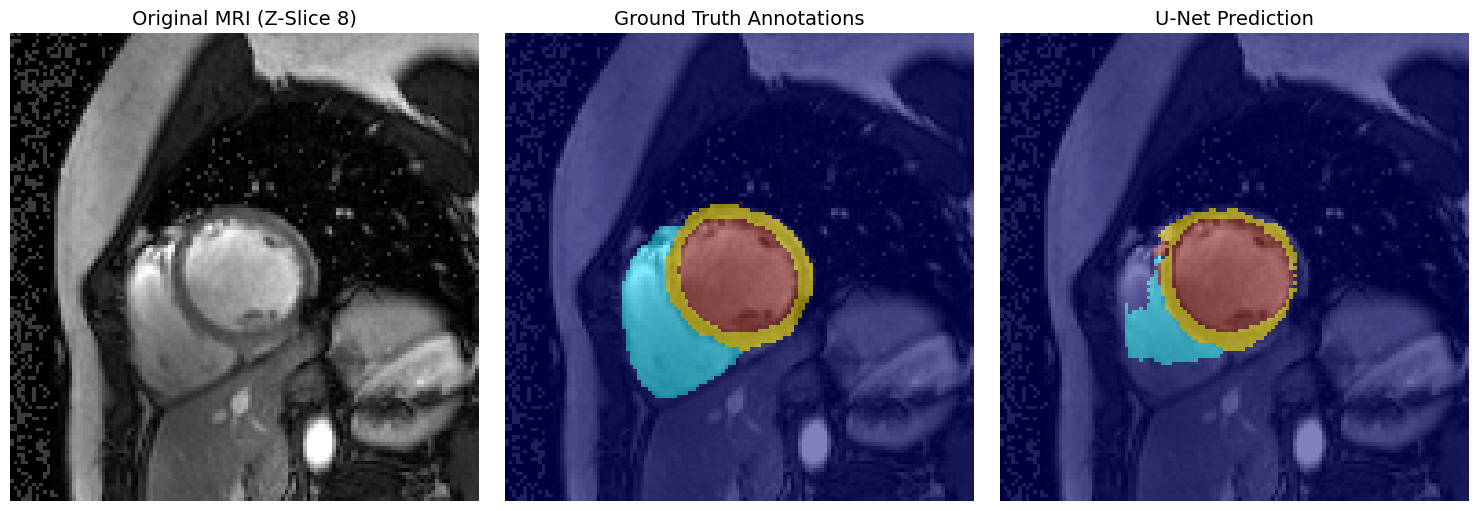

In [ ]:
import matplotlib.pyplot as plt
from monai.transforms import CenterSpatialCropd

# 1. Prepare the Validation Data
val_data = data_dicts[train_size:]
print(f"Allocated {len(val_data)} unseen volumes for validation.")

# We use Center Crop for validation to consistently get the middle of the heart
val_transforms = Compose([
    LoadACDCH5d(keys=["h5_path"]),
    NormalizeIntensityd(keys=["image"], nonzero=True, channel_wise=True),
    SpatialPadd(keys=["image", "label"], spatial_size=(16, 256, 240)),
    CenterSpatialCropd(keys=["image", "label"], roi_size=(16, 128, 128)),
    ToTensord(keys=["image", "label"]),
])

val_ds = CacheDataset(data=val_data, transform=val_transforms, cache_rate=1.0, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=1, num_workers=2)

# 2. Run Inference
model.eval()
with torch.no_grad():
    for val_batch in val_loader:
        val_inputs = val_batch["image"].to(device)
        val_labels = val_batch["label"].to(device)

        # Get raw logits from the model
        val_outputs = model(val_inputs)

        # Collapse the 4 one-hot channels into a single prediction image
        # by taking the class with the highest probability (argmax)
        val_preds = torch.argmax(val_outputs, dim=1, keepdim=True)

        # We only need one patient to visualize
        break

# 3. Visualize a cross-section (Slice 8 out of 16)
slice_idx = 8
plt.figure(figsize=(15, 5))

# Plot A: Original MRI
plt.subplot(1, 3, 1)
plt.title(f"Original MRI (Z-Slice {slice_idx})", fontsize=14)
plt.imshow(val_inputs[0, 0, slice_idx, :, :].cpu().numpy(), cmap="gray")
plt.axis("off")

# Plot B: Ground Truth Mask
plt.subplot(1, 3, 2)
plt.title("Ground Truth Annotations", fontsize=14)
# We plot the label over the MRI for context
plt.imshow(val_inputs[0, 0, slice_idx, :, :].cpu().numpy(), cmap="gray")
plt.imshow(val_labels[0, 0, slice_idx, :, :].cpu().numpy(), cmap="jet", alpha=0.5)
plt.axis("off")

# Plot C: U-Net Prediction
plt.subplot(1, 3, 3)
plt.title("U-Net Prediction", fontsize=14)
plt.imshow(val_inputs[0, 0, slice_idx, :, :].cpu().numpy(), cmap="gray")
plt.imshow(val_preds[0, 0, slice_idx, :, :].cpu().numpy(), cmap="jet", alpha=0.5)
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

print("Extracting clinical metrics from 3D masks...")
results = []

model.eval()
with torch.no_grad():
    for i, val_batch in enumerate(val_loader):
        inputs = val_batch["image"].to(device)

        # Get the 3D prediction
        preds = torch.argmax(model(inputs), dim=1, keepdim=True).cpu().numpy()

        # In ACDC: 1=RV, 2=Myocardium, 3=LV Cavity
        # We count the total voxels to determine structural volume
        myo_volume = np.sum(preds == 2)
        lv_volume = np.sum(preds == 3)

        # Calculate a proxy for Hypertrophy (wall thickness vs cavity size)
        # Higher index = thicker walls relative to the chamber (classic HCM sign)
        hypertrophy_index = myo_volume / (lv_volume + 1e-5)

        results.append({
            "patient_id": f"val_patient_{i+1}",
            "myocardium_volume_px": myo_volume,
            "lv_cavity_volume_px": lv_volume,
            "hypertrophy_index": round(hypertrophy_index, 3)
        })

# Create a DataFrame and save to CSV
df = pd.DataFrame(results)
csv_path = "/content/hcm_morphology_metrics.csv"
df.to_csv(csv_path, index=False)

print(f"Metrics saved to {csv_path}")
display(df.head())

Extracting clinical metrics from 3D masks...
Metrics saved to /content/hcm_morphology_metrics.csv


,patient_id,myocardium_volume_px,lv_cavity_volume_px,hypertrophy_index
0,val_patient_1,4039,8600,0.470
1,val_patient_2,4362,6573,0.664
2,val_patient_3,6340,7915,0.801
3,val_patient_4,7470,3369,2.217
4,val_patient_5,2904,1881,1.544


In [ ]:
import torch
import numpy as np
import pandas as pd
from monai.metrics import DiceMetric
from monai.utils import set_determinism

set_determinism(seed=42)

# Initialize Dice metric calculator
dice_metric_clean = DiceMetric(include_background=False, reduction="mean")
dice_metric_noisy = DiceMetric(include_background=False, reduction="mean")

print("Initiating model stress-test and robustness evaluation...")

model.eval()
with torch.no_grad():
    for val_batch in val_loader:
        inputs = val_batch["image"].to(device)
        labels = val_batch["label"].to(device)

        # 1. Baseline: Evaluate clean images
        clean_outputs = model(inputs)
        clean_preds = torch.nn.functional.one_hot(
            torch.argmax(clean_outputs, dim=1), num_classes=4
        ).permute(0, 4, 1, 2, 3)
        dice_metric_clean(y_pred=clean_preds, y=labels)

        # 2. Adversarial: Inject simulated scanner noise (Mean=0, Std=0.5)
        noise = torch.randn_like(inputs) * 0.5
        noisy_inputs = inputs + noise

        noisy_outputs = model(noisy_inputs)
        noisy_preds = torch.nn.functional.one_hot(
            torch.argmax(noisy_outputs, dim=1), num_classes=4
        ).permute(0, 4, 1, 2, 3)
        dice_metric_noisy(y_pred=noisy_preds, y=labels)

# Aggregate and compute final scores
clean_score = dice_metric_clean.aggregate().item()
noisy_score = dice_metric_noisy.aggregate().item()
degradation = (clean_score - noisy_score) / clean_score * 100

print("-" * 30)
print(f"Clean MRI Dice Score:  {clean_score:.3f}")
print(f"Noisy MRI Dice Score:  {noisy_score:.3f}")
print(f"Performance Degradation: {degradation:.1f}%")
print("-" * 30)

Initiating model stress-test and robustness evaluation...
------------------------------
Clean MRI Dice Score:  0.718
Noisy MRI Dice Score:  0.634
Performance Degradation: 11.7%
------------------------------
